# 04 · Modelos base

En este notebook entrenamos los dos modelos base que pide el enunciado:

- **Regresión logística**, como modelo lineal.
- **Árbol de decisión**, como modelo sencillo. Lo elegimos en vez de KNN porque se puede interpretar (se ven las reglas que usa) y porque es la base de los ensembles del notebook 05 (Random Forest, Gradient Boosting y XGBoost), así veremos cuánto mejoran sobre un solo árbol.

Para los dos usamos el esquema del notebook 03: ajuste de hiperparámetros con validación cruzada de 5 particiones sobre el train, en cada una de las 12 configuraciones de preprocesamiento, eligiendo por F1 macro. El test no se toca aquí.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

sys.path.append(str(Path.cwd().parent))
from src.config import SEED, RESULTS_DIR, CLASS_NAMES
from src.validacion import (cargar_datos, dividir_train_test, METRICAS, ajustar_modelo,
                            mejor_configuracion, entrenar_final, comparar_modelos, guardar_tabla)

COLUMNAS = ["imputacion", "escalado", "balanceo", "mejores_parametros", "f1_macro_media", "f1_macro_std",
            "recall_alto_media", "bal_acc_media", "accuracy_media", "sobreajuste", "segundos"]

## 1. Datos

Misma partición que en los notebooks 02 y 03.

In [2]:
X, y = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(X, y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1803, 27)  Test: (451, 27)


In [3]:
def mapa_configuraciones(tabla, metrica, titulo, ax):
    # una fila por imputación/escalado y una columna por balanceo
    t = tabla.assign(prep=tabla.imputacion + " / " + tabla.escalado)
    t = t.pivot(index="prep", columns="balanceo", values=metrica)[["ninguno", "class_weight", "smotenc"]]
    sns.heatmap(t, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(titulo)
    ax.set_xlabel("balanceo")
    ax.set_ylabel("imputación / escalado")

## 2. Regresión logística

El hiperparámetro principal es `C`, la inversa de la regularización: con `C` pequeño los coeficientes se encogen más y el modelo es más simple. Probamos valores en escala logarítmica de 0,001 a 100. Usamos la regularización L2 que viene por defecto. Con 3 clases sklearn ajusta una logística multinomial.

In [4]:
tabla_log, busquedas_log = ajustar_modelo("logistica", LogisticRegression(max_iter=5000),
                                          {"C": [0.001, 0.01, 0.1, 1, 10, 100]}, X_train, y_train)
guardar_tabla(tabla_log, "modelos_base_logistica")
tabla_log[COLUMNAS].round(3)

logistica | mediana-estandar-ninguno         F1 macro 0.638 (±0.027)  recall alto 0.659  [3 s]


logistica | mediana-estandar-class_weight    F1 macro 0.631 (±0.025)  recall alto 0.748  [0 s]


logistica | mediana-estandar-smotenc         F1 macro 0.623 (±0.023)  recall alto 0.723  [1 s]


logistica | mediana-yeojohnson-ninguno       F1 macro 0.643 (±0.036)  recall alto 0.670  [0 s]


logistica | mediana-yeojohnson-class_weight  F1 macro 0.638 (±0.028)  recall alto 0.759  [0 s]


logistica | mediana-yeojohnson-smotenc       F1 macro 0.632 (±0.020)  recall alto 0.726  [1 s]


... (3 outputs left out)

logistica | knn-yeojohnson-ninguno           F1 macro 0.643 (±0.031)  recall alto 0.662  [1 s]


logistica | knn-yeojohnson-class_weight      F1 macro 0.639 (±0.033)  recall alto 0.748  [1 s]


logistica | knn-yeojohnson-smotenc           F1 macro 0.631 (±0.021)  recall alto 0.715  [1 s]


,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,f1_macro_std,recall_alto_media,bal_acc_media,accuracy_media,sobreajuste,segundos
0,knn,yeojohnson,ninguno,{'C': 0.1},0.643,0.031,0.662,0.641,0.681,0.021,0.7
1,mediana,yeojohnson,ninguno,{'C': 100},0.643,0.036,0.670,0.642,0.678,0.025,0.3
2,knn,yeojohnson,class_weight,{'C': 1},0.639,0.033,0.748,0.651,0.658,0.031,0.6
3,mediana,estandar,ninguno,{'C': 1},0.638,0.027,0.659,0.636,0.673,0.020,3.3
4,mediana,yeojohnson,class_weight,{'C': 0.1},0.638,0.028,0.759,0.652,0.657,0.026,0.4
5,knn,estandar,ninguno,{'C': 1},0.636,0.029,0.659,0.634,0.673,0.021,0.6
6,knn,estandar,class_weight,{'C': 10},0.633,0.031,0.737,0.645,0.653,0.031,0.5
7,mediana,yeojohnson,smotenc,{'C': 1},0.632,0.020,0.726,0.642,0.650,0.032,0.7
8,knn,yeojohnson,smotenc,{'C': 10},0.631,0.021,0.715,0.640,0.651,0.031,1.0
9,mediana,estandar,class_weight,{'C': 0.1},0.631,0.025,0.748,0.645,0.653,0.031,0.2


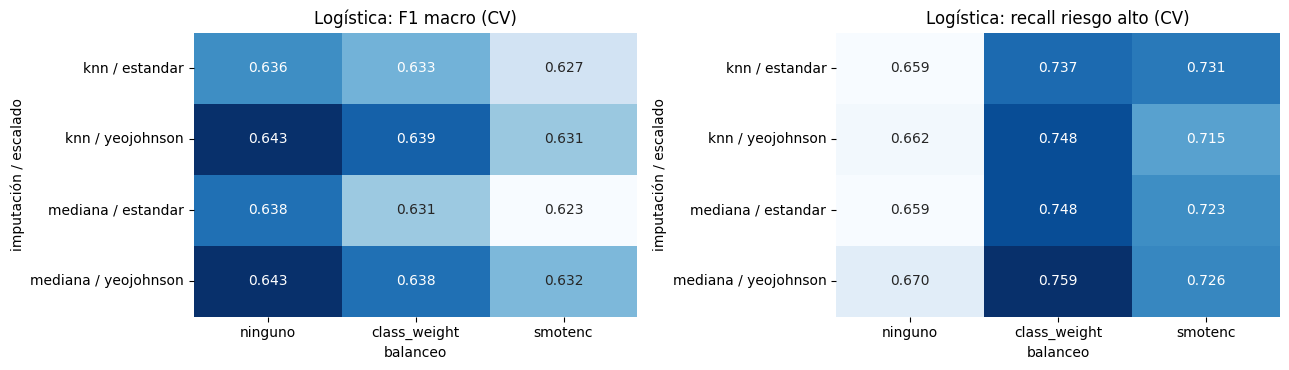

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
mapa_configuraciones(tabla_log, "f1_macro_media", "Logística: F1 macro (CV)", axes[0])
mapa_configuraciones(tabla_log, "recall_alto_media", "Logística: recall riesgo alto (CV)", axes[1])
plt.tight_layout()
plt.savefig(RESULTS_DIR / "modelos_base_logistica_configuraciones.png", dpi=150)
plt.show()

- El F1 macro casi no cambia entre configuraciones (0,62-0,64). Yeo-Johnson va un poco mejor que el z-score, seguramente porque la logística es lineal y le viene bien que las variables sean más simétricas.
- El balanceo es lo que más cambia el recall de riesgo alto: de 0,66 sin balancear a 0,75 con `class_weight`.
- El sobreajuste es muy pequeño (unas 2-3 centésimas de F1 entre train y validación), lo normal en un modelo lineal.

Como el F1 macro de la mejor configuración y de la mejor con `class_weight` está prácticamente empatado, para la comparación final nos quedamos también con la mejor con `class_weight`, que detecta bastantes más pacientes de riesgo alto.

### Coeficientes

Entrenamos la mejor configuración con todo el train y miramos qué variables pesan más para predecir riesgo alto. Como las variables están escaladas, los coeficientes se pueden comparar entre sí.

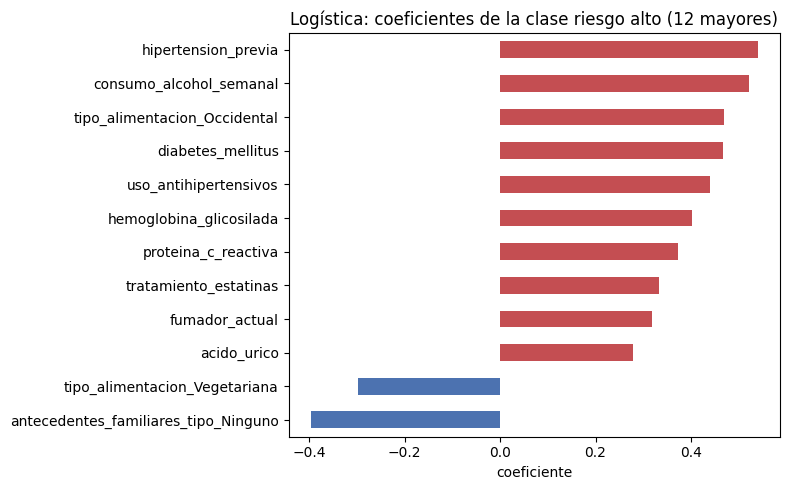

In [6]:
mejor_log = mejor_configuracion(tabla_log)
pipe_log = entrenar_final(LogisticRegression(max_iter=5000), mejor_log, X_train, y_train)
nombres = pipe_log[:-1].transform(X_train.head()).columns
coef = pd.DataFrame(pipe_log[-1].coef_.T, index=nombres, columns=[CLASS_NAMES[c] for c in pipe_log[-1].classes_])
top = coef["Alto"].sort_values(key=abs, ascending=False).head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top.plot.barh(ax=ax, color=["#C44E52" if v > 0 else "#4C72B0" for v in top])
ax.set_title("Logística: coeficientes de la clase riesgo alto (12 mayores)")
ax.set_xlabel("coeficiente")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "modelos_base_logistica_coeficientes.png", dpi=150)
plt.show()

Las variables que más empujan hacia riesgo alto son la hipertensión previa, el consumo de alcohol, la alimentación occidental, la diabetes, el uso de antihipertensivos, la hemoglobina glicosilada y la proteína C reactiva. Las que más restan son no tener antecedentes familiares y la alimentación vegetariana. Tienen sentido clínico porque son factores de riesgo cardiovascular conocidos. Es una ventaja de la logística: se puede explicar a un médico por qué clasifica así.

## 3. Árbol de decisión

Ajustamos los hiperparámetros que controlan el tamaño del árbol, que es lo que evita el sobreajuste:

- `max_depth`: profundidad máxima (3 a 10, o sin límite).
- `min_samples_leaf`: mínimo de pacientes en cada hoja (1 a 40).
- `criterion`: gini o entropía.

En total son 70 combinaciones por configuración. Para el árbol el escalado no cambia nada, pero lo dejamos para tratar todos los modelos igual.

In [7]:
tabla_arbol, busquedas_arbol = ajustar_modelo(
    "arbol", DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 5, 10, 20, 40],
     "criterion": ["gini", "entropy"]},
    X_train, y_train)
guardar_tabla(tabla_arbol, "modelos_base_arbol")
tabla_arbol[COLUMNAS].round(3)

arbol | mediana-estandar-ninguno         F1 macro 0.531 (±0.028)  recall alto 0.471  [2 s]


arbol | mediana-estandar-class_weight    F1 macro 0.531 (±0.014)  recall alto 0.579  [2 s]


arbol | mediana-estandar-smotenc         F1 macro 0.535 (±0.028)  recall alto 0.635  [6 s]


arbol | mediana-yeojohnson-ninguno       F1 macro 0.530 (±0.029)  recall alto 0.471  [3 s]


arbol | mediana-yeojohnson-class_weight  F1 macro 0.532 (±0.014)  recall alto 0.579  [3 s]


arbol | mediana-yeojohnson-smotenc       F1 macro 0.540 (±0.008)  recall alto 0.543  [6 s]


... (3 outputs left out)

arbol | knn-yeojohnson-ninguno           F1 macro 0.524 (±0.025)  recall alto 0.490  [6 s]


arbol | knn-yeojohnson-class_weight      F1 macro 0.528 (±0.011)  recall alto 0.643  [6 s]


arbol | knn-yeojohnson-smotenc           F1 macro 0.529 (±0.020)  recall alto 0.601  [9 s]


,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,f1_macro_std,recall_alto_media,bal_acc_media,accuracy_media,sobreajuste,segundos
0,knn,estandar,smotenc,"{'criterion': 'entropy', 'max_depth': 8, 'min_...",0.546,0.028,0.612,0.561,0.557,0.073,8.3
1,mediana,yeojohnson,smotenc,"{'criterion': 'gini', 'max_depth': 10, 'min_sa...",0.540,0.008,0.543,0.546,0.565,0.253,6.3
2,knn,estandar,class_weight,"{'criterion': 'entropy', 'max_depth': 8, 'min_...",0.540,0.020,0.612,0.555,0.554,0.207,5.2
3,mediana,estandar,smotenc,"{'criterion': 'entropy', 'max_depth': 4, 'min_...",0.535,0.028,0.635,0.554,0.542,0.030,5.5
4,mediana,yeojohnson,class_weight,"{'criterion': 'gini', 'max_depth': 10, 'min_sa...",0.532,0.014,0.579,0.542,0.552,0.219,3.0
5,mediana,estandar,class_weight,"{'criterion': 'gini', 'max_depth': 10, 'min_sa...",0.531,0.014,0.579,0.542,0.551,0.220,2.1
6,mediana,estandar,ninguno,"{'criterion': 'gini', 'max_depth': 8, 'min_sam...",0.531,0.028,0.471,0.525,0.566,0.219,2.0
7,mediana,yeojohnson,ninguno,"{'criterion': 'gini', 'max_depth': 8, 'min_sam...",0.530,0.029,0.471,0.525,0.565,0.220,3.0
8,knn,yeojohnson,smotenc,"{'criterion': 'gini', 'max_depth': 8, 'min_sam...",0.529,0.020,0.601,0.542,0.539,0.141,9.3
9,knn,estandar,ninguno,"{'criterion': 'gini', 'max_depth': 8, 'min_sam...",0.529,0.037,0.465,0.524,0.568,0.084,5.1


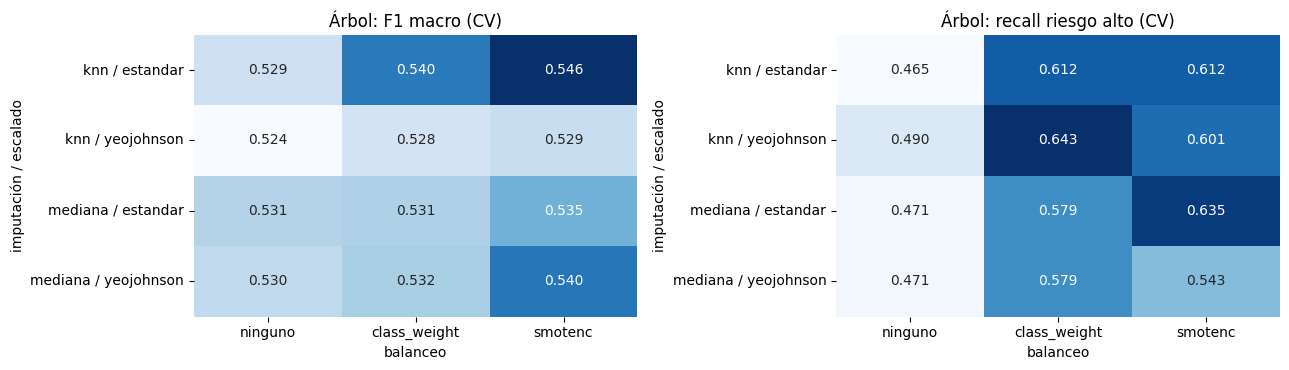

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
mapa_configuraciones(tabla_arbol, "f1_macro_media", "Árbol: F1 macro (CV)", axes[0])
mapa_configuraciones(tabla_arbol, "recall_alto_media", "Árbol: recall riesgo alto (CV)", axes[1])
plt.tight_layout()
plt.savefig(RESULTS_DIR / "modelos_base_arbol_configuraciones.png", dpi=150)
plt.show()

### Profundidad y sobreajuste

Con la mejor configuración, vemos cómo cambian el F1 de train y de validación según la profundidad, con hojas de 1 paciente (sin limitar) y con hojas de 40 pacientes (el mejor valor).

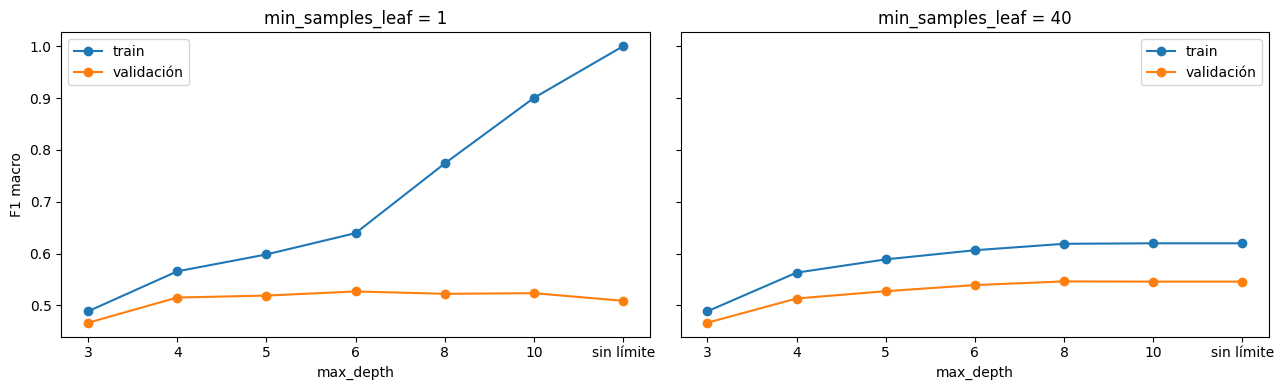

In [9]:
mejor_arbol = mejor_configuracion(tabla_arbol)
res = pd.DataFrame(busquedas_arbol[f"{mejor_arbol.imputacion}-{mejor_arbol.escalado}-{mejor_arbol.balanceo}"].cv_results_)
res = res[res["param_modelo__criterion"] == mejor_arbol.mejores_parametros["criterion"]]
res["profundidad"] = res["param_modelo__max_depth"].astype(object).fillna("sin límite").astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, hoja in zip(axes, [1, 40]):
    curva = res[res["param_modelo__min_samples_leaf"] == hoja]
    ax.plot(curva["profundidad"], curva["mean_train_f1_macro"], "o-", label="train")
    ax.plot(curva["profundidad"], curva["mean_test_f1_macro"], "o-", label="validación")
    ax.set_title(f"min_samples_leaf = {hoja}")
    ax.set_xlabel("max_depth")
    ax.legend()
axes[0].set_ylabel("F1 macro")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "modelos_base_arbol_profundidad.png", dpi=150)
plt.show()

Con hojas de 1 paciente, cuanto más profundo es el árbol más sube el F1 de train (hasta casi 1 sin límite) y el de validación no mejora: el árbol memoriza el train. Con hojas de 40 pacientes la diferencia entre train y validación es mucho menor, y por eso en la búsqueda gana un árbol con hojas grandes. Aun así, el mejor árbol se queda bastante por debajo de la logística.

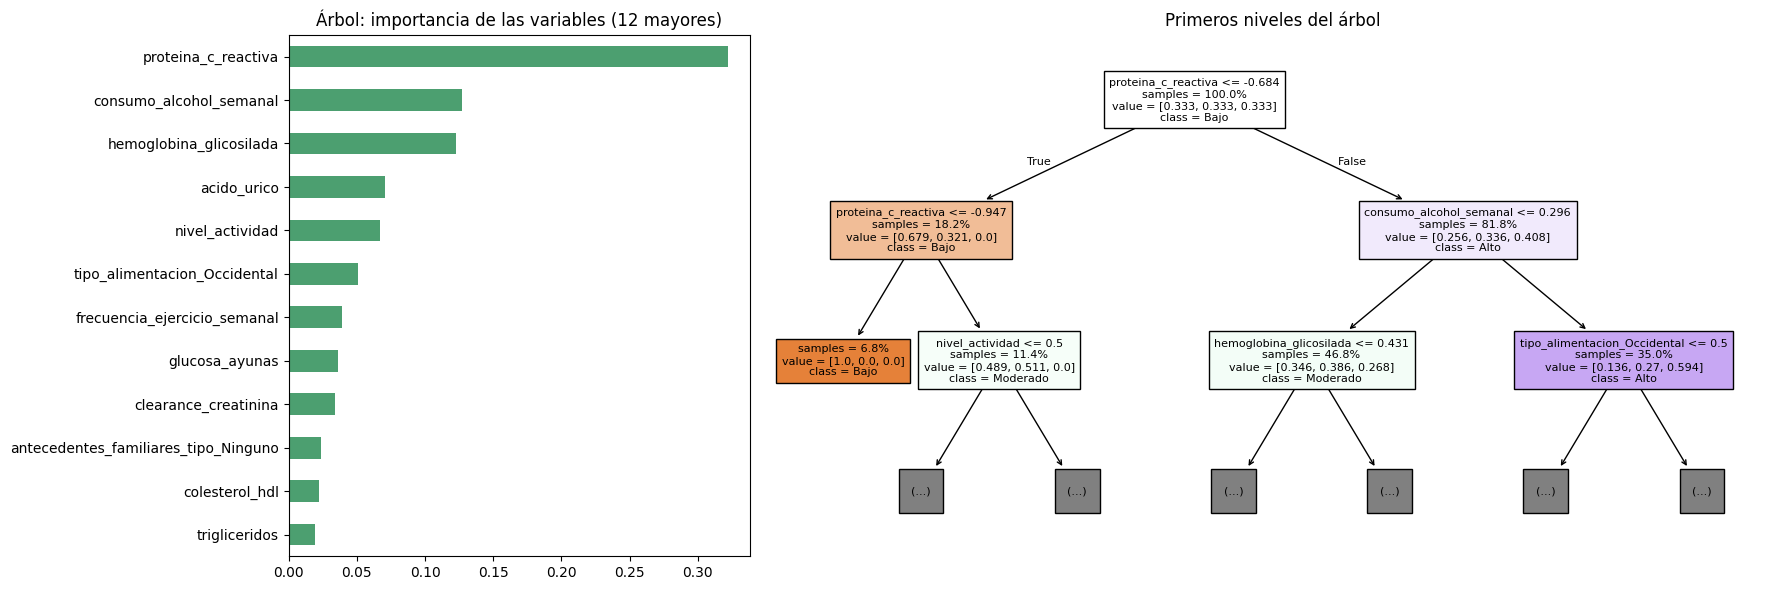

In [10]:
pipe_arbol = entrenar_final(DecisionTreeClassifier(random_state=SEED), mejor_arbol, X_train, y_train)
nombres_arbol = pipe_arbol[:-1].transform(X_train.head()).columns
importancias = pd.Series(pipe_arbol[-1].feature_importances_, index=nombres_arbol).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 2.2]})
importancias.head(12).sort_values().plot.barh(ax=axes[0], color="#4C9F70")
axes[0].set_title("Árbol: importancia de las variables (12 mayores)")
plot_tree(pipe_arbol[-1], max_depth=2, feature_names=list(nombres_arbol),
          class_names=[CLASS_NAMES[c] for c in sorted(CLASS_NAMES)], filled=True,
          impurity=False, proportion=True, fontsize=8, ax=axes[1])
axes[1].set_title("Primeros niveles del árbol")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "modelos_base_arbol_importancias.png", dpi=150)
plt.show()

Las primeras divisiones del árbol usan la proteína C reactiva, el alcohol, la hemoglobina glicosilada y la alimentación occidental, que también están entre las que más pesan en la logística. Los dos modelos coinciden bastante en qué es importante. El problema del árbol es que divide con cortes bruscos de una variable cada vez, y aquí el riesgo parece depender de muchas variables a la vez con efectos pequeños (lo vimos en el EDA). Eso lo recoge mejor un modelo lineal o un ensemble de muchos árboles.

## 4. Comparación de los modelos base

Comparamos con la validación cruzada 5x3 (las mismas 15 particiones para todos) la mejor logística, la mejor logística con `class_weight` y el mejor árbol. Guardamos los resultados de cada partición para comparar después con los ensembles y para los tests estadísticos.

In [11]:
log_pesos = tabla_log[tabla_log.balanceo == "class_weight"].iloc[0]
candidatos = {
    "logistica": (LogisticRegression(max_iter=5000), mejor_log),
    "logistica_class_weight": (LogisticRegression(max_iter=5000), log_pesos),
    "arbol": (DecisionTreeClassifier(random_state=SEED), mejor_arbol),
}
cv_repetida = comparar_modelos(candidatos, X_train, y_train)
guardar_tabla(cv_repetida, "cv_repetida_modelos_base")
cv_repetida.groupby("modelo")[list(METRICAS)].agg(["mean", "std"]).round(3)

f1_macro        bal_acc        recall_alto         \
                           mean    std    mean    std        mean    std   
modelo                                                                     
arbol                     0.528  0.028   0.543  0.027       0.607  0.059   
logistica                 0.641  0.029   0.641  0.029       0.670  0.052   
logistica_class_weight    0.640  0.026   0.653  0.029       0.753  0.057   

                       accuracy         
                           mean    std  
modelo                                  
arbol                     0.544  0.025  
logistica                 0.680  0.025  
logistica_class_weight    0.660  0.021

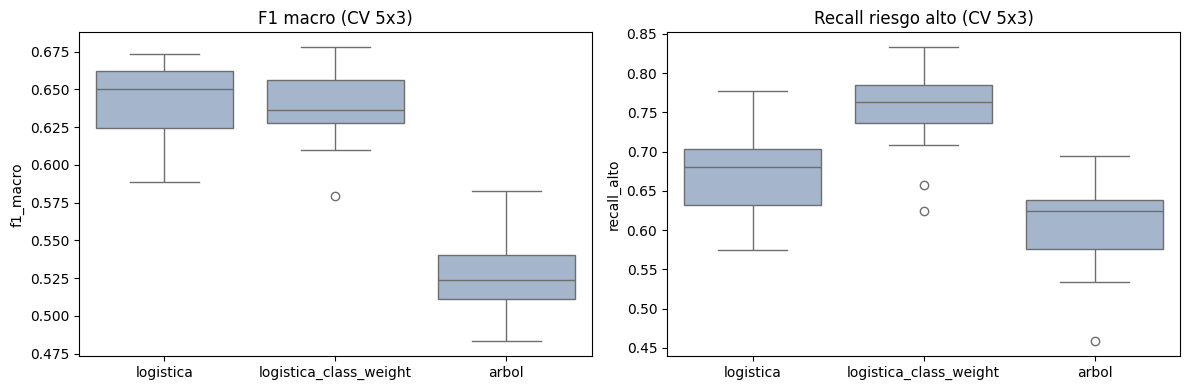

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m, titulo in [(axes[0], "f1_macro", "F1 macro"), (axes[1], "recall_alto", "Recall riesgo alto")]:
    sns.boxplot(data=cv_repetida, x="modelo", y=m, ax=ax, color="#9DB4D3")
    ax.set_title(f"{titulo} (CV 5x3)")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "modelos_base_comparacion.png", dpi=150)
plt.show()

In [13]:
mejores = pd.DataFrame([{"modelo": nombre, **fila[["imputacion", "escalado", "balanceo", "mejores_parametros",
                                                    "f1_macro_media", "recall_alto_media", "bal_acc_media"]]}
                        for nombre, (_, fila) in candidatos.items()])
guardar_tabla(mejores, "mejores_modelos_base")
mejores.round(3)

,modelo,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,recall_alto_media,bal_acc_media
0,logistica,knn,yeojohnson,ninguno,{'C': 0.1},0.643,0.662,0.641
1,logistica_class_weight,knn,yeojohnson,class_weight,{'C': 1},0.639,0.748,0.651
2,arbol,knn,estandar,smotenc,"{'criterion': 'entropy', 'max_depth': 8, 'min_...",0.546,0.612,0.561


## 5. Resumen

- La **regresión logística** es el mejor modelo base: F1 macro de 0,64 en validación cruzada, casi sin sobreajuste y fácil de interpretar. Con `class_weight` mantiene el F1 y sube el recall de riesgo alto de 0,66 a 0,75.
- El **árbol de decisión** se queda en torno a 0,53-0,55 de F1 macro y sobreajusta en cuanto se le deja crecer. Sus variables más importantes coinciden bastante con las de la logística.
- El preprocesamiento que mejor va depende del modelo: a la logística le viene algo mejor Yeo-Johnson, y a los dos les sube el recall de riesgo alto con `class_weight` o SMOTE-NC (en el árbol, de 0,49 sin balancear a 0,64).

Los mejores ajustes están en `results/mejores_modelos_base.csv` y los resultados por partición en `results/cv_repetida_modelos_base.csv`. La evaluación en test se hará al final con todos los modelos.